# California Housing Regression: OLS, Ridge, and Lasso

**Goal:** predict median California house values and compare ordinary least squares with L2 and L1 regularization.

All learned preprocessing is nested in scikit-learn pipelines. The holdout test set remains unseen until final model evaluation.

## Workflow

1. Audit missing values, the target distribution, and numerical correlations.
2. Make an 80/20 train-test split.
3. Create interpretable housing-density ratios and income interactions.
4. Impute, standardize, and encode data within pipelines.
5. Inspect VIF for multicollinearity, then tune Ridge and Lasso using 5-fold CV.
6. Compare RMSE, MAE, and R²; examine predictions and residual distributions.

In [1]:
from pathlib import Path
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.exceptions import ConvergenceWarning
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Lasso, LinearRegression, Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
SEED, TEST_SIZE, CV_FOLDS = 42, 0.20, 5
warnings.filterwarnings("ignore", category=ConvergenceWarning)
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

def find_project_root():
    for candidate in (Path.cwd(), Path.cwd().parent):
        if (candidate / "data" / "raw" / "housing.csv").exists():
            return candidate
    raise FileNotFoundError("Start Jupyter from the project root or notebooks folder.")

PROJECT_ROOT = find_project_root()
# Ensure the project package can be imported whether Jupyter starts in the root or notebooks/ folder.
import sys
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.housing_features import HousingFeatures

DATA_PATH = PROJECT_ROOT / "data" / "raw" / "housing.csv"
ARTIFACTS_DIR = PROJECT_ROOT / "artifacts"
ARTIFACTS_DIR.mkdir(exist_ok=True)
print(f"Using data: {DATA_PATH}")

Using data: d:\Datheon_Machine_Learning_-_Data_Science_Internship\california-housing-regression\data\raw\housing.csv


## 1. Data quality and exploratory analysis

Rows: 20,640 | Columns: 10 | Duplicate rows: 0


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.230,37.880,41.000,880.000,129.000,322.000,126.000,8.325,"452,600.000",NEAR BAY
1,-122.220,37.860,21.000,"7,099.000","1,106.000","2,401.000","1,138.000",8.301,"358,500.000",NEAR BAY
2,-122.240,37.850,52.000,"1,467.000",190.000,496.000,177.000,7.257,"352,100.000",NEAR BAY
3,-122.250,37.850,52.000,"1,274.000",235.000,558.000,219.000,5.643,"341,300.000",NEAR BAY
4,-122.250,37.850,52.000,"1,627.000",280.000,565.000,259.000,3.846,"342,200.000",NEAR BAY


,dtype,missing_count,missing_pct,unique_values
total_bedrooms,float64,207,1.003,1923
median_income,float64,0,0.000,12928
total_rooms,float64,0,0.000,5926
population,float64,0,0.000,3888
median_house_value,float64,0,0.000,3842
households,float64,0,0.000,1815
latitude,float64,0,0.000,862
longitude,float64,0,0.000,844
housing_median_age,float64,0,0.000,52
ocean_proximity,object,0,0.000,5


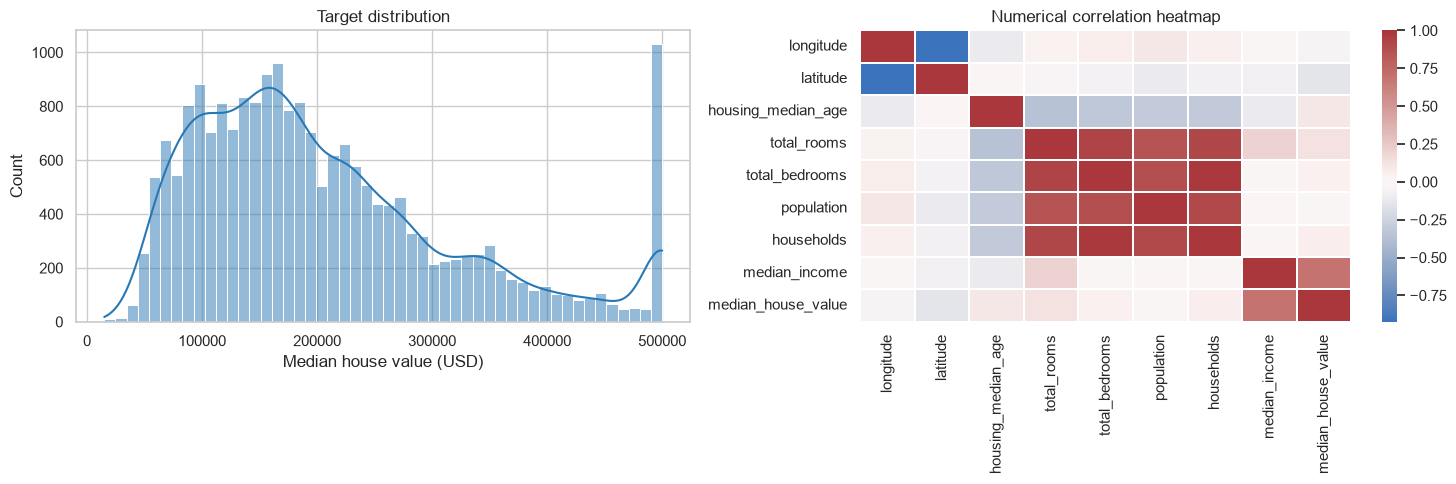

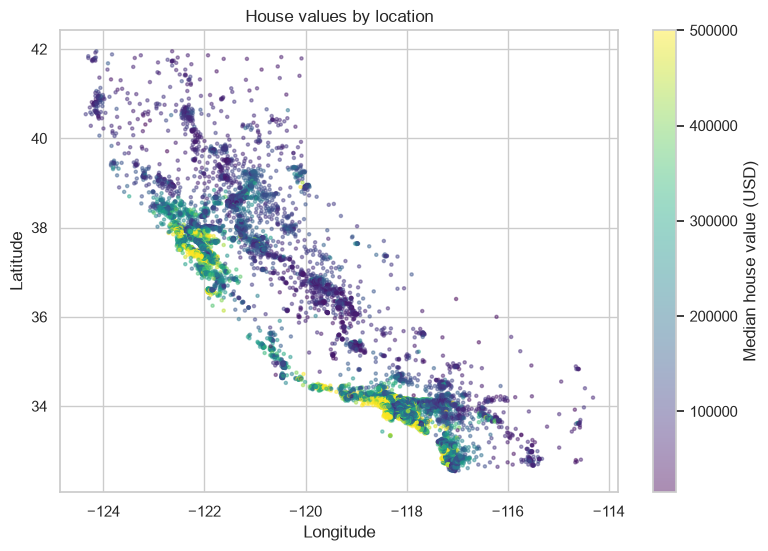

In [2]:
housing = pd.read_csv(DATA_PATH)
TARGET = "median_house_value"
assert TARGET in housing.columns and housing[TARGET].notna().all()

print(f"Rows: {len(housing):,} | Columns: {housing.shape[1]} | Duplicate rows: {housing.duplicated().sum():,}")
display(housing.head())

audit = pd.DataFrame({
    "dtype": housing.dtypes.astype(str),
    "missing_count": housing.isna().sum(),
    "missing_pct": housing.isna().mean().mul(100),
    "unique_values": housing.nunique(),
}).sort_values(["missing_count", "unique_values"], ascending=False)
display(audit)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.histplot(housing[TARGET], bins=50, kde=True, color="#2878B5", ax=axes[0])
axes[0].set(title="Target distribution", xlabel="Median house value (USD)")
corr = housing.select_dtypes(include=np.number).corr()
sns.heatmap(corr, cmap="vlag", center=0, linewidths=0.25, ax=axes[1])
axes[1].set_title("Numerical correlation heatmap")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 6))
points = plt.scatter(housing.longitude, housing.latitude, c=housing[TARGET], s=5, alpha=.45, cmap="viridis")
plt.colorbar(points, label="Median house value (USD)")
plt.title("House values by location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

## 2. Feature engineering, preprocessing, and multicollinearity

The feature transformer adds room, bedroom, and population density variables plus income interactions. A median imputer handles numeric nulls after the engineered fields are created. The encoder drops one reference category, avoiding the dummy-variable trap.

VIF is calculated on the training split after imputation, scaling, and encoding. High VIF motivates regularization, but does not automatically remove a variable.

,feature,VIF
4,numeric__total_bedrooms,51.061
6,numeric__households,47.099
7,numeric__median_income,21.520
1,numeric__latitude,20.456
3,numeric__total_rooms,19.712
0,numeric__longitude,18.424
11,numeric__income_x_rooms_per_household,18.124
12,numeric__income_x_age,9.215
5,numeric__population,6.970
2,numeric__housing_median_age,5.600


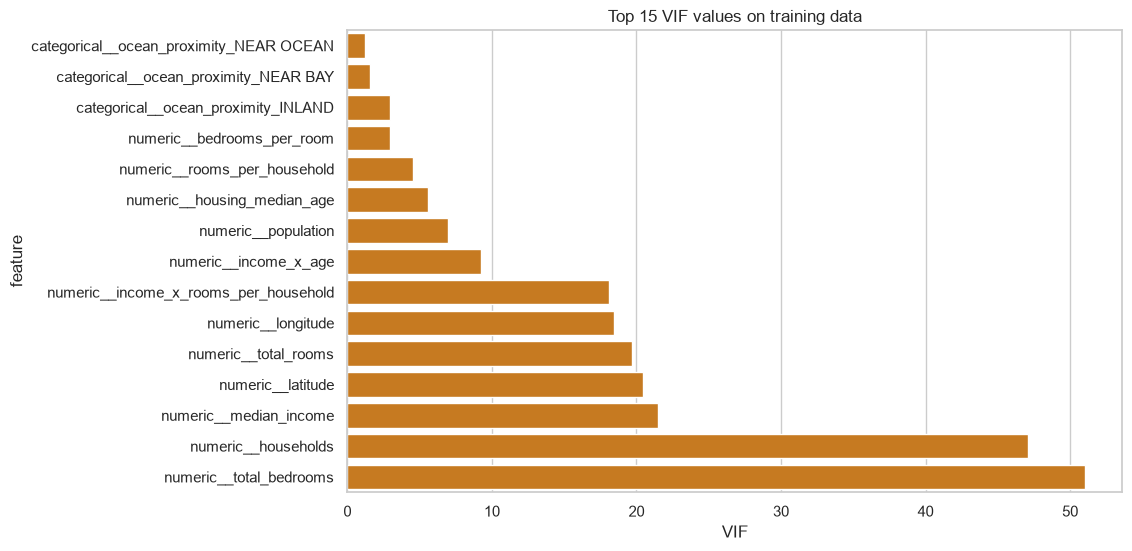

In [3]:
X, y = housing.drop(columns=TARGET), housing[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=TEST_SIZE, random_state=SEED)

categorical = ["ocean_proximity"]
engineered_numeric = [
    "rooms_per_household", "bedrooms_per_room", "population_per_household",
    "income_x_rooms_per_household", "income_x_age",
]
numeric = [name for name in X.columns if name not in categorical] + engineered_numeric

preprocessor = ColumnTransformer([
    ("numeric", Pipeline([("imputer", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), numeric),
    ("categorical", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                              ("encode", OneHotEncoder(drop="first", handle_unknown="ignore"))]), categorical),
])

def pipeline(model):
    return Pipeline([("features", HousingFeatures()), ("preprocessor", preprocessor), ("model", model)])

diagnostic_features = HousingFeatures().fit_transform(X_train)
diagnostic_preprocessor = preprocessor.fit(diagnostic_features)
matrix = diagnostic_preprocessor.transform(diagnostic_features)
if hasattr(matrix, "toarray"):
    matrix = matrix.toarray()
vif = np.diag(np.linalg.pinv(np.corrcoef(matrix, rowvar=False)))
vif_table = pd.DataFrame({
    "feature": diagnostic_preprocessor.get_feature_names_out(), "VIF": vif
}).replace([np.inf, -np.inf], np.nan).sort_values("VIF", ascending=False)
display(vif_table.head(15))

plt.figure(figsize=(10, 6))
sns.barplot(data=vif_table.head(15).sort_values("VIF"), x="VIF", y="feature", color="#E17C05")
plt.title("Top 15 VIF values on training data")
plt.show()

## 3. Model selection and held-out evaluation

In [4]:
ols = pipeline(LinearRegression())
ridge_search = GridSearchCV(
    pipeline(Ridge()),
    {"model__alpha": np.logspace(-2, 2, 5)},
    scoring="neg_root_mean_squared_error", cv=CV_FOLDS, n_jobs=1,
)
lasso_search = GridSearchCV(
    pipeline(Lasso(max_iter=50_000, tol=1e-3)),
    {"model__alpha": np.logspace(-2, 2, 5)},
    scoring="neg_root_mean_squared_error", cv=CV_FOLDS, n_jobs=1,
)

ols.fit(X_train, y_train)
ridge_search.fit(X_train, y_train)
lasso_search.fit(X_train, y_train)
models = {"OLS": ols, "Ridge": ridge_search.best_estimator_, "Lasso": lasso_search.best_estimator_}

records, predictions = [], {}
for name, model in models.items():
    pred = model.predict(X_test)
    predictions[name] = pred
    records.append({
        "model": name,
        "RMSE": np.sqrt(mean_squared_error(y_test, pred)),
        "MAE": mean_absolute_error(y_test, pred),
        "R2": r2_score(y_test, pred),
        "best_alpha": ridge_search.best_params_["model__alpha"] if name == "Ridge"
                      else lasso_search.best_params_["model__alpha"] if name == "Lasso" else np.nan,
        "CV_RMSE": -ridge_search.best_score_ if name == "Ridge"
                   else -lasso_search.best_score_ if name == "Lasso" else np.nan,
    })

results = pd.DataFrame(records).sort_values("RMSE").reset_index(drop=True)
display(results.style.format({
    "RMSE": "USD {:,.0f}", "MAE": "USD {:,.0f}", "R2": "{:.3f}",
    "best_alpha": "{:.4g}", "CV_RMSE": "USD {:,.0f}",
}))

best_name = results.loc[0, "model"]
results.to_csv(ARTIFACTS_DIR / "model_comparison.csv", index=False)
joblib.dump(models[best_name], ARTIFACTS_DIR / "best_model.joblib")
print(f"Best holdout RMSE: {best_name}. Outputs saved in {ARTIFACTS_DIR}.")

,model,RMSE,MAE,R2,best_alpha,CV_RMSE
0,OLS,"USD 68,845","USD 49,459",0.638,nan,USD nan
1,Lasso,"USD 68,846","USD 49,459",0.638,1,"USD 67,652"
2,Ridge,"USD 68,855","USD 49,465",0.638,1,"USD 67,651"


Best holdout RMSE: OLS. Outputs saved in d:\Datheon_Machine_Learning_-_Data_Science_Internship\california-housing-regression\artifacts.


## 4. Predicted-versus-actual and residual curves

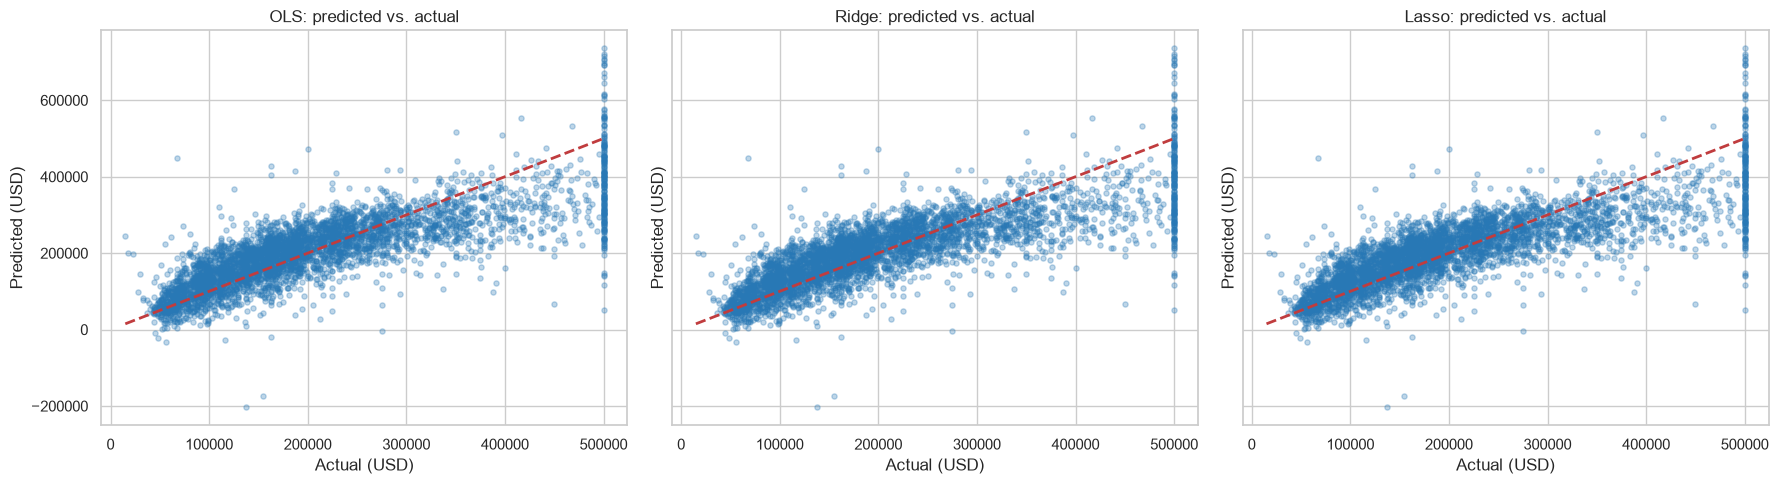

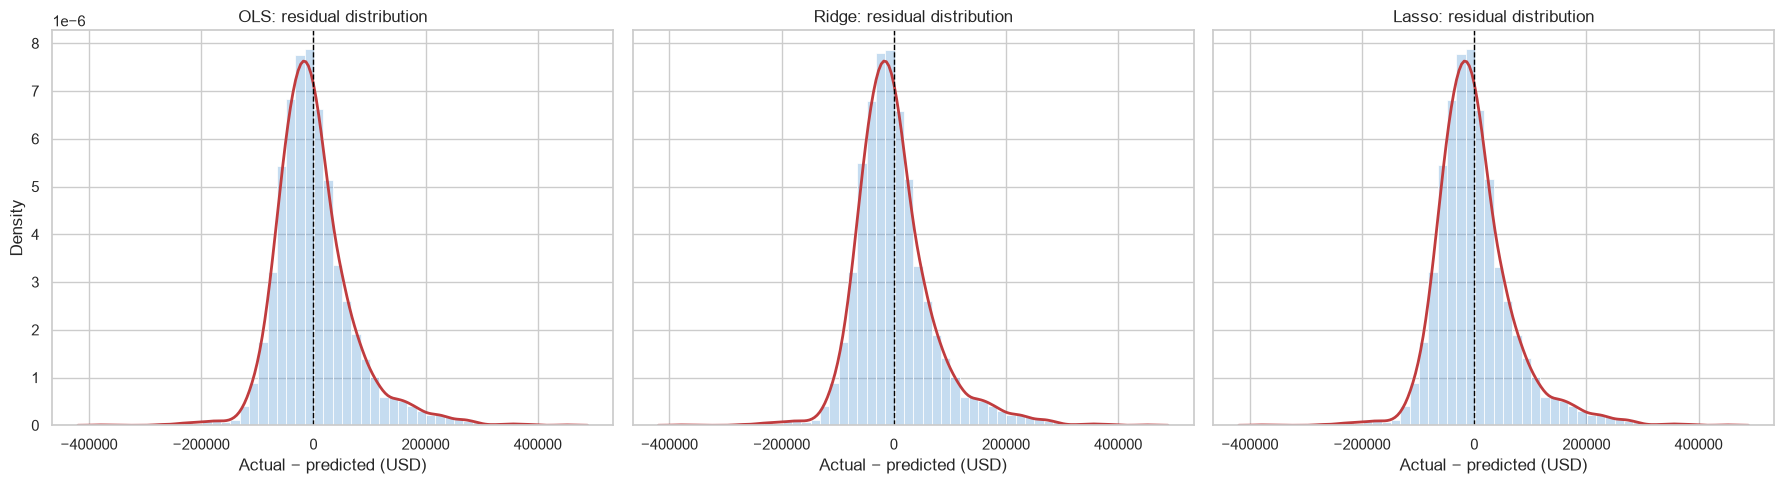

In [5]:
limits = [y_test.min(), y_test.max()]
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True, sharey=True)
for ax, (name, pred) in zip(axes, predictions.items()):
    ax.scatter(y_test, pred, s=14, alpha=.3, color="#2878B5")
    ax.plot(limits, limits, "--", color="#C03C3E", linewidth=2)
    ax.set(title=f"{name}: predicted vs. actual", xlabel="Actual (USD)", ylabel="Predicted (USD)")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, (name, pred) in zip(axes, predictions.items()):
    residuals = y_test - pred
    sns.histplot(residuals, bins=50, stat="density", alpha=.35, color="#5B9BD5", ax=ax)
    sns.kdeplot(residuals, color="#C03C3E", linewidth=2, ax=ax)
    ax.axvline(0, color="black", linestyle="--", linewidth=1)
    ax.set(title=f"{name}: residual distribution", xlabel="Actual − predicted (USD)")
plt.tight_layout()
plt.show()

## 5. Coefficients and conclusion

Lasso retained 17 of 17 post-processed features.


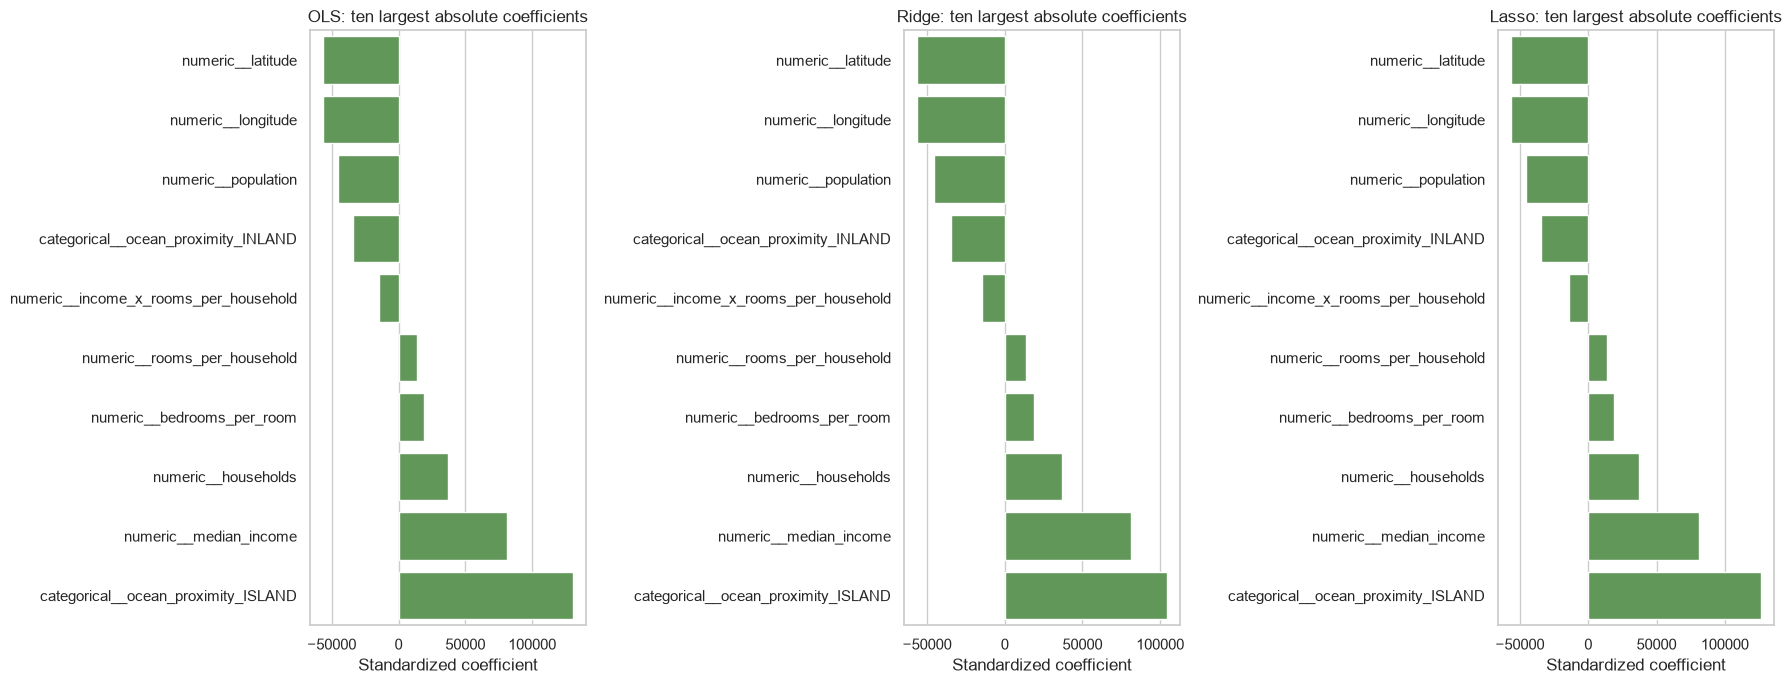

,model,RMSE,MAE,R2,best_alpha,CV_RMSE
0,OLS,"68,845.002","49,458.665",0.638,NaN,NaN
1,Lasso,"68,846.393","49,459.234",0.638,1.000,"67,651.904"
2,Ridge,"68,855.229","49,465.345",0.638,1.000,"67,650.566"


Conclusion: OLS has the lowest held-out RMSE for this split. Use the CV result and residual shapes alongside holdout metrics when selecting a deployment model.


In [6]:
coefficient_frames = []
for name, model in models.items():
    names = model.named_steps["preprocessor"].get_feature_names_out()
    coefficients = model.named_steps["model"].coef_
    coefficient_frames.append(pd.DataFrame({"feature": names, "coefficient": coefficients, "model": name}))
coefficient_comparison = pd.concat(coefficient_frames, ignore_index=True)
lasso_nonzero = (coefficient_comparison.query("model == 'Lasso'").coefficient.abs() > 1e-8).sum()
lasso_total = len(coefficient_comparison.query("model == 'Lasso'"))
print(f"Lasso retained {lasso_nonzero} of {lasso_total} post-processed features.")

top = (coefficient_comparison.assign(abs_coef=lambda df: df.coefficient.abs())
       .sort_values("abs_coef", ascending=False).groupby("model", group_keys=False).head(10))
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, name in zip(axes, models):
    data = top.query("model == @name").sort_values("coefficient")
    sns.barplot(data=data, x="coefficient", y="feature", color="#59A14F", ax=ax)
    ax.set(title=f"{name}: ten largest absolute coefficients", xlabel="Standardized coefficient", ylabel="")
plt.tight_layout()
plt.show()

display(results)
print(f"Conclusion: {best_name} has the lowest held-out RMSE for this split. Use the CV result and residual shapes alongside holdout metrics when selecting a deployment model.")